<div style="border:4px solid #b00020; background:#ffe5e8; color:#600010; padding:14px 18px; border-radius:6px;">
<h2 style="margin:0 0 8px 0; color:#b00020;">&#9888; WARNING: THE SAMPLE TIME HAS CHANGED</h2>
<p style="margin:4px 0;"><b>The phonon sample period is 0.8 &micro;s (1.25 MHz), not 1.6 &micro;s (625 kHz).</b> A 4096-sample trace is 3.2768 ms. Until 2026-10-22 this notebook used 1.6 &micro;s, which was wrong.</p>
<p style="margin:4px 0;">What this means: times and energies are <b>half</b> of what older versions showed, frequencies are <b>doubled</b> (the axis now reaches 625 kHz), PSDs are halved and ASDs are divided by 1.41. Anything counted in samples or counts (cuts, selections, pulse heights) is unchanged.</p>
<p style="margin:4px 0;">This notebook was re-run with the new value (the library default, <code>PulseConfig</code> without <code>sample_period_s</code>). See <i>The sample period</i> in <code>python/README.md</code>.</p>
</div>

<div style="border:4px solid #b00020; background:#ffe5e8; color:#600010; padding:14px 18px; border-radius:6px;">
<h2 style="margin:0 0 8px 0; color:#b00020;">&#9888; WARNING: THE CHANNEL MAP HAS CHANGED</h2>
<p style="margin:4px 0;"><b>This notebook used the wrong table columns for the channel names.</b> The series is read out on <b>Side 2</b>, so the right columns of the Run 76 Setup table are <i>Label</i> and <i>HV output, Side 2 readout</i> (not <i>DCRC (2-sided)</i>). There are <b>six sensors, all on Side 2</b>: DCRC1 pA, pB, pD = <code>Side2pC</code>, <code>Side2pF</code>, <code>Side2pE</code>; DCRC3 pA, pB, pD = <code>Side2pB</code>, <code>Side2pA</code>, <code>Side2pD</code>. DCRC4 pA is the <b>NaI trigger input</b> (not a phonon sensor) and the other five inputs are not connected. See <code>python/pulse_channels.py</code> (since 2026-10-22).</p>
<p style="margin:4px 0;">Names of the dump channels that changed: (0, 3) <code>Side1pF</code> is now <code>Side2pE</code>, (1, 0) <code>Side1pE</code> is <code>Side2pB</code>, (1, 1) <code>Side1pB</code> is <code>Side2pA</code>, (1, 3) <code>Side2pE</code> is <code>Side2pD</code>, (2, 0) <code>Side2pB</code> is the NaI input. (0, 0) <code>Side2pC</code> and (0, 1) <code>Side2pF</code> are as before. Everything keyed by (detector, channel) is unchanged.</p>
<p style="margin:4px 0;"><b>What changed in this notebook:</b></p>
<ul style="margin:4px 0;">
<li>The six channels are now the six sensors, all on Side 2; the NaI trigger input (DCRC4 pA, called <code>Side2pB</code> before) is not a channel of this study. The checks of its pulses are now a one-line diagnostic.</li>
<li>Renamed channels in the text and tables: <code>Side1pB</code> is <code>Side2pA</code> (the one that ramps most), <code>Side1pE</code> is <code>Side2pB</code>, <code>Side1pF</code> is <code>Side2pE</code>, <code>Side2pE</code> is <code>Side2pD</code>.</li>
<li>Numbers unchanged: 274 randoms with a pulse, 734 pulse-free, the drift tables, the correlations (0.82 to 0.97), 629 / 50 / 15 events with 0, 6 or 1 large drifts, 122 odd events (121 fail the cut). The global cut over the six sensors keeps 34 pulse-free randoms.</li>
</ul>
</div>

# Baseline drift: does one channel ever drift while the others do not? Series 07221203_2025, dump F0001

The failures of the quiet-noise cut (`quiet-cut-failures-buddy.ipynb`) turned out to be noise on a **slow baseline drift**, mostly a downward ramp, and the kept traces still sag a little. If that drift is a property of the event, for example a slow recovery in the readout that every channel of the board sees, then the channels of an event should drift together. If one channel has a large drift while the others on the same event have none, that would be odd, and it is also what a cut that is evaluated on each channel's own trace, and then combined, would be sensitive to.

Questions, in order:

1. Which randoms contain a pulse, and how big is the drift of the rest? (sections 1 and 2)
2. Do the channels of an event drift together? (section 3)
3. Are there events where one channel has a large drift and the others do not, more often than chance would give? (section 4)
4. What do those events look like, and does the quiet-noise cut catch them? (sections 5 and 6)
5. Are there events where one channel sees a pulse and the others do not? (section 7)

The **drift** of a trace is the total change of its least-squares straight line across the trace, in ADC counts (a negative drift is a sag). It is measured on the baseline-subtracted traces with the leading glitch samples skipped, for the events recorded as randoms (`pc.randoms`), the same events as the noise notebook before any quiet-noise cut. **The randoms also contain real pulses**: in about a quarter of them at least one channel shows a pulse, a step of tens to hundreds of counts with a slow recovery. The drift of such a trace is just the pulse, so the drift questions (sections 2 to 6) use only the *pulse-free* randoms, and section 7 looks at the pulses separately. The statistical error of a drift from the white noise alone is about 0.1 counts, so drifts of a count or more are real. The channels are the 6 working ones of the noise notebook, the six sensors of the Side-2 readout (the NaI trigger input and the five unconnected inputs are not sensors); channel names come from `pulse_channels` and are provisional. Run with the `darkmatter_cli_env` kernel.

**Caveat carried over from Note 2a.** `pulse_cuts.randoms` assumes the dump's trigger-type labels are swapped (events recorded as `Physics` are taken to be randoms). This is a working assumption, not confirmed.

*Author: buddy. Draft.*

In [1]:
import sys
from pathlib import Path
# Find the project's python folder from wherever this notebook is, however deep.
_here = Path.cwd().resolve()
REPO = next((p for p in [_here, *_here.parents] if (p / "python" / "pulse_io.py").exists()), None)
assert REPO, "Start Jupyter from inside the NSDF-Data folder."
sys.path.insert(0, str(REPO / "python"))

import numpy as np
import matplotlib.pyplot as plt
from nsdf_dark_matter.idx import load_all_data

import pulse_io as pio
import pulse_quantities as pq
import pulse_operations as po
import pulse_cuts as pc
import pulse_channels as pch

def short_label(det, ch):
    """Channel name with its readout board, e.g. 'Side2pC (DCRC1)'."""
    return f"{pch.channel_name(det, ch)} ({pch.channel_info(det, ch).dcrc})"

SENSORS = [(c.detector, c.channel) for c in pch.sensor_channels()]     # the six sensors of the Side-2 readout
BOARD_COLOUR = {"DCRC1": "#d95f02", "DCRC3": "#1f77b4"}               # orange: DCRC1 (Side2pC, pF, pE); blue: DCRC3 (Side2pB, pA, pD)

def inactive_text(c):
    """What to write in the tile of an input that is not a sensor."""
    if c.role == pch.NAI_TRIGGER:
        return "NaI trigger input" + chr(10) + "(not a phonon sensor)"
    return "not connected"
from pulse_config import PulseConfig

import check_environment
check_environment.check()

Environment OK: Python 3.12.15, and the 8 packages in requirements.txt match.


C:\Users\villanoa\AppData\Local\Temp\ipykernel_12084\2204443403.py:23: UserWarning: sensor_channels is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and channels 0 to 3 = board inputs pA to pD is assumed; not yet confirmed against the run's ODB
  SENSORS = [(c.detector, c.channel) for c in pch.sensor_channels()]     # the six sensors of the Side-2 readout


[]

## 1. Load the dump and measure the drift of every trace

For each of the 12 inputs and every event (only the six sensors are used from section 1 on): the drift of the baseline-subtracted, glitch-trimmed trace (a straight-line fit, as in section 10 of the noise notebook), the scatter left after removing that line, and whether the trace passes the quiet-noise cut of Notes 2 and 2a (Tight excursion band and `log10(bstd) < 0.5`) on its own. A trace is said to **contain a pulse** if the scatter left after removing the line is more than 3 times the median of that channel's randoms; noise and a ramp leave only the noise scatter (1.4 to 2.6 counts), while a pulse leaves tens to hundreds of counts. A *pulse-free* random has no pulse in any working channel.

In [2]:
DUMP = "07221203_2025_F0001"
config_500 = PulseConfig(pretrigger_samples=500, glitch_samples=10)
cdms = load_all_data(str(Path.home() / "idx" / DUMP))
det_ids = {det: pio.filter_by_detector(cdms.get_detector_ids(), det) for det in range(3)}

# The three boards share their events, in the same order, so one event list serves every channel.
event_numbers = np.array([int(pio.event_id(i)) for i in det_ids[0]])
is_random = pc.randoms(pio.trigger_types(cdms, det_ids[0]))
for det in (1, 2):
    assert np.array_equal(event_numbers, [int(pio.event_id(i)) for i in det_ids[det]])
    assert np.array_equal(is_random, pc.randoms(pio.trigger_types(cdms, det_ids[det])))

def processed(pulse_array):
    # baseline-subtract (500-sample window) and drop the leading glitch samples
    return po.trim_glitch(po.baseline_subtract(pulse_array, config_500), config_500)

def fit_line(traces):
    """Least-squares straight line of each trace: returns (slope in counts per sample, offset in counts)."""
    t = np.arange(traces.shape[-1], dtype=float)
    design = np.stack([t, np.ones_like(t)], axis=1)
    coef, *_ = np.linalg.lstsq(design, traces.T, rcond=None)
    return coef[0], coef[1]

n_samples = processed(np.zeros((1, 4096))).shape[-1]
info = {}    # (detector, channel) -> dict of arrays with one entry per event
for det in range(3):
    for ch in range(4):
        _, p = pio.load_channel_batch(cdms, det_ids[det], ch)
        flat = processed(p)
        slope, offset = fit_line(flat)
        t = np.arange(n_samples)
        with np.errstate(all="ignore"):
            quiet = pc.excursion_band(p, config_500) & (np.log10(pq.bstd(p, config_500)) < 0.5)
        info[(det, ch)] = dict(drift=slope * n_samples, slope=slope, offset=offset, quiet=quiet,
                               resid_rms=np.sqrt(np.mean((flat - (np.outer(slope, t) + offset[:, None])) ** 2, axis=1)))

# The working channels are the six sensors of the Side-2 readout (pch.sensor_channels()); the NaI trigger input and the five
# unconnected inputs are not sensors and are left out. A sensor works if its own cut keeps at least 2 randoms.
working = [k for k in SENSORS if (info[k]["quiet"] & is_random).sum() >= 2]
mixed = list(working)                                                   # the six sensors, on DCRC1 and DCRC3
drift = np.array([info[k]["drift"] for k in working]).T                  # (events, working channels)
# A trace contains a pulse if what is left after removing its straight line is far above the noise of its channel
for k in working:
    info[k]["pulse"] = info[k]["resid_rms"] > 3 * np.median(info[k]["resid_rms"][is_random])
has_pulse = np.array([info[k]["pulse"] for k in working]).T            # (events, working channels)
pulse_free = is_random & ~has_pulse.any(axis=1)
nai_key = next(k for k in info if pch.channel_info(*k).role == pch.NAI_TRIGGER)     # DCRC4 pA, the NaI trigger input
info[nai_key]["pulse"] = info[nai_key]["resid_rms"] > 3 * np.median(info[nai_key]["resid_rms"][is_random])
print(f"{len(event_numbers)} events, {is_random.sum()} randoms; {len(working)} working channels (the six sensors, on DCRC1 and DCRC3)")
print(f"randoms with a pulse in at least one working channel: {(is_random & has_pulse.any(axis=1)).sum()}; pulse-free randoms: {pulse_free.sum()}")
print("pulse in this channel: " + ", ".join(f"{pch.channel_name(*k)} {(is_random & info[k]['pulse']).sum()}" for k in working))
print("expected error of a drift from the white noise alone:",
      f"{np.median([np.median(info[k]['resid_rms']) * np.sqrt(12 / n_samples) for k in working]):.2f} counts")

C:\Users\villanoa\AppData\Local\Temp\ipykernel_12084\21769944.py:8: UserWarning: randoms is marked under_development: assumes the dump's trigger_type labels are swapped relative to their names: events recorded as 'Physics' are taken to be randoms (fixed-count random triggers) and 'Unknown' to be real triggers. That mapping is a working assumption from 07221203_2025_F0001 (see Note 2a), not confirmed against the DAQ configuration or the nsdf library
  is_random = pc.randoms(pio.trigger_types(cdms, det_ids[0]))
C:\Users\villanoa\AppData\Local\Temp\ipykernel_12084\21769944.py:11: UserWarning: randoms is marked under_development: assumes the dump's trigger_type labels are swapped relative to their names: events recorded as 'Physics' are taken to be randoms (fixed-count random triggers) and 'Unknown' to be real triggers. That mapping is a working assumption from 07221203_2025_F0001 (see Note 2a), not confirmed against the DAQ configuration or the nsdf library
  assert np.array_equal(is_rand

1517 events, 1008 randoms; 6 working channels (the six sensors, on DCRC1 and DCRC3)
randoms with a pulse in at least one working channel: 274; pulse-free randoms: 734
pulse in this channel: Side2pC 214, Side2pF 240, Side2pE 217, Side2pB 237, Side2pA 253, Side2pD 227
expected error of a drift from the white noise alone: 0.13 counts


C:\Users\villanoa\AppData\Local\Temp\ipykernel_12084\21769944.py:47: UserWarning: channel_info is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and channels 0 to 3 = board inputs pA to pD is assumed; not yet confirmed against the run's ODB
  nai_key = next(k for k in info if pch.channel_info(*k).role == pch.NAI_TRIGGER)     # DCRC4 pA, the NaI trigger input
C:\Users\villanoa\AppData\Local\Temp\ipykernel_12084\21769944.py:51: UserWarning: channel_name is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and channels 0 to 3 = board inputs pA to pD is assumed; not yet confirmed against the run's ODB
  print("pulse in this channel: " + ", ".join(f"{pch.channel_name(*k)} {(is_random & info[k]['pulse']).sum()}" for k in working))
C:\Users\villanoa\Research\NSDF-Data-buddy2\python\pulse_channels.py:129: UserWarning: channel_info is marked under_development: the dum

## 2. How big is the drift?

The distribution of the drift of the **pulse-free** randoms in each working channel: median, 16th to 84th percentile and 1st to 99th percentile, and the fraction with a sag of more than 5 counts.

C:\Users\villanoa\AppData\Local\Temp\ipykernel_12084\2204443403.py:21: UserWarning: channel_name is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and channels 0 to 3 = board inputs pA to pD is assumed; not yet confirmed against the run's ODB
  return f"{pch.channel_name(det, ch)} ({pch.channel_info(det, ch).dcrc})"
C:\Users\villanoa\AppData\Local\Temp\ipykernel_12084\2204443403.py:21: UserWarning: channel_info is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and channels 0 to 3 = board inputs pA to pD is assumed; not yet confirmed against the run's ODB
  return f"{pch.channel_name(det, ch)} ({pch.channel_info(det, ch).dcrc})"
C:\Users\villanoa\AppData\Local\Temp\ipykernel_12084\1555549765.py:11: UserWarning: channel_name is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and channels 0 to 3

channel                       median          16-84%           1-99%  sag > 5
Side2pC (DCRC1)                 -5.9   -14.0..-2.6     -49.4..-0.1       59%
Side2pF (DCRC1)                 -9.3   -22.6..-3.7     -95.1..-0.5       76%
Side2pE (DCRC1)                 -7.4   -17.2..-3.1     -69.1..0.8        68%
Side2pB (DCRC3)                -11.4   -31.5..-3.3    -127.2..1.9        77%
Side2pA (DCRC3)                -12.0   -35.5..-3.9    -136.2..1.0        78%
Side2pD (DCRC3)                -11.3   -29.1..-3.7    -116.0..1.2        77%


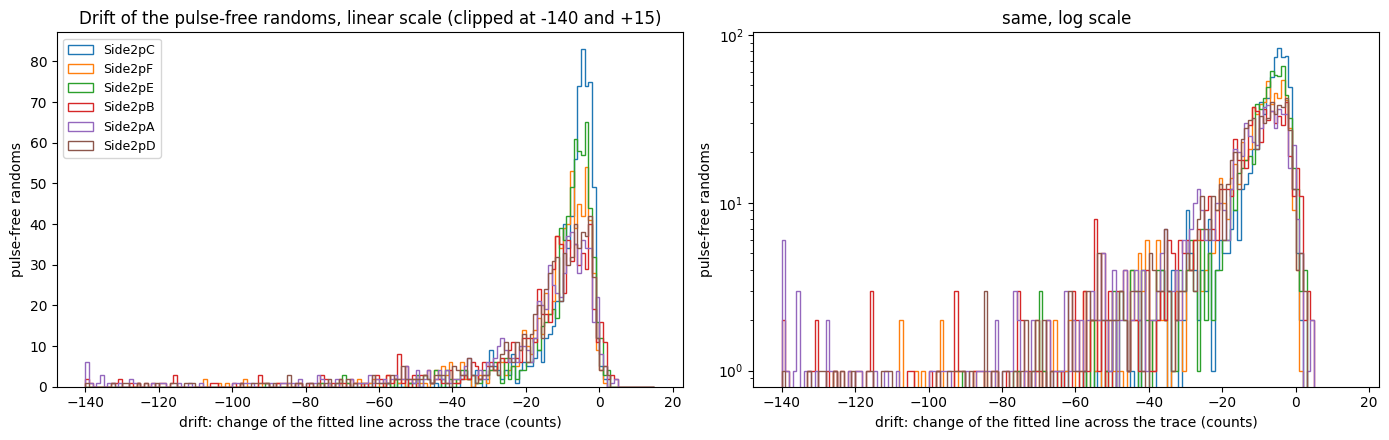

In [3]:
R = pulse_free
print(f"{'channel':<28}{'median':>8}{'16-84%':>16}{'1-99%':>16}{'sag > 5':>9}")
for i, k in enumerate(working):
    d = drift[R, i]
    print(f"{short_label(*k):<28}{np.median(d):>8.1f}{np.percentile(d, 16):>8.1f}..{np.percentile(d, 84):<6.1f}"
          f"{np.percentile(d, 1):>8.1f}..{np.percentile(d, 99):<6.1f}{(d < -5).mean():>8.0%}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
bins = np.linspace(-140, 15, 156)
for i, k in enumerate(working):
    axes[0].hist(np.clip(drift[R, i], -140, 15), bins=bins, histtype="step", label=pch.channel_name(*k))
    axes[1].hist(np.clip(drift[R, i], -140, 15), bins=bins, histtype="step")
axes[1].set_yscale("log")
for ax in axes:
    ax.set_xlabel("drift: change of the fitted line across the trace (counts)")
    ax.set_ylabel("pulse-free randoms")
axes[0].legend(fontsize=9)
axes[0].set_title("Drift of the pulse-free randoms, linear scale (clipped at -140 and +15)")
axes[1].set_title("same, log scale")
fig.tight_layout()
plt.savefig(f"figures/drift-distribution-{DUMP}.png", dpi=110)
plt.show()

## 3. Do the channels of an event drift together?

The rank correlation (Spearman) between the drifts of every pair of working channels, over the pulse-free randoms; the matrix is ordered by board. Below it, the drift of one channel against another for three pairs: two channels of the same board (DCRC1), two of different boards (DCRC1 and DCRC3), and two of the same board (DCRC3). If the drift is a property of the event, the points follow a line; if the channels drift independently, they form a round cloud.

C:\Users\villanoa\AppData\Local\Temp\ipykernel_12084\2629188144.py:6: UserWarning: channel_name is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and channels 0 to 3 = board inputs pA to pD is assumed; not yet confirmed against the run's ODB
  names = [pch.channel_name(*k) for k in working]
C:\Users\villanoa\AppData\Local\Temp\ipykernel_12084\2629188144.py:11: UserWarning: channel_info is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and channels 0 to 3 = board inputs pA to pD is assumed; not yet confirmed against the run's ODB
  axes[0].set_yticks(range(len(names))); axes[0].set_yticklabels([f"{nm} ({pch.channel_info(*k).dcrc})" for nm, k in zip(names, working)])
C:\Users\villanoa\AppData\Local\Temp\ipykernel_12084\2629188144.py:20: UserWarning: channel_info is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,D

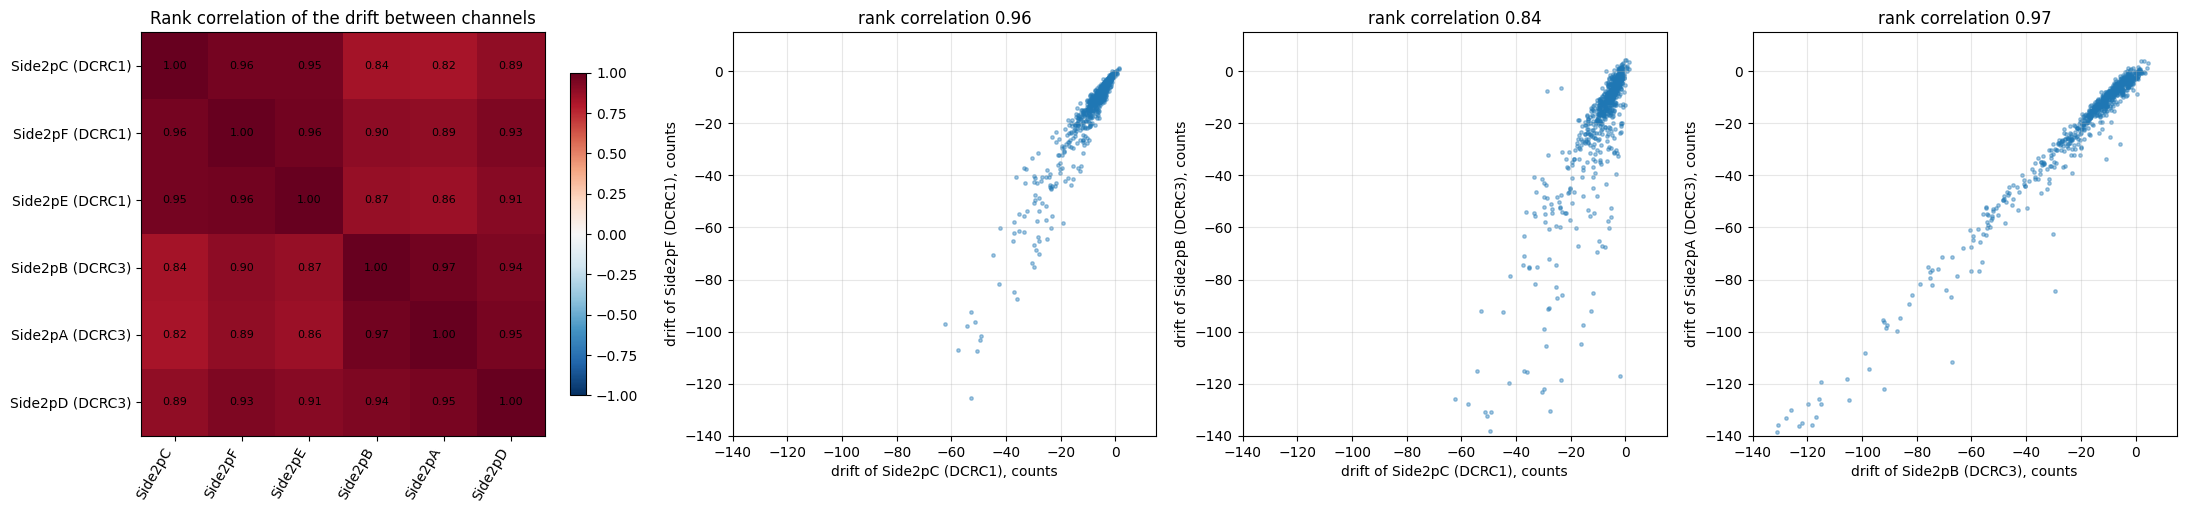

correlation between the six DCRC1 and DCRC3 channels: min 0.82, median 0.91, max 0.97


In [4]:
def ranks(a):
    return np.argsort(np.argsort(a)).astype(float)

rank = np.array([ranks(drift[R, i]) for i in range(len(working))])
corr = np.corrcoef(rank)
names = [pch.channel_name(*k) for k in working]

fig, axes = plt.subplots(1, 4, figsize=(22, 5), gridspec_kw=dict(width_ratios=[1.2, 1, 1, 1]))
im = axes[0].imshow(corr, vmin=-1, vmax=1, cmap="RdBu_r")
axes[0].set_xticks(range(len(names))); axes[0].set_xticklabels(names, rotation=60, ha="right")
axes[0].set_yticks(range(len(names))); axes[0].set_yticklabels([f"{nm} ({pch.channel_info(*k).dcrc})" for nm, k in zip(names, working)])
for a in range(len(names)):
    for b in range(len(names)):
        axes[0].text(b, a, f"{corr[a, b]:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(im, ax=axes[0], shrink=0.8)
axes[0].set_title("Rank correlation of the drift between channels")
pairs = [(0, 1), (0, 3), (3, 4)]
for ax, (a, b) in zip(axes[1:], pairs):
    ax.scatter(drift[R, a], drift[R, b], s=6, alpha=0.4)
    ax.set_xlabel(f"drift of {names[a]} ({pch.channel_info(*working[a]).dcrc}), counts")
    ax.set_ylabel(f"drift of {names[b]} ({pch.channel_info(*working[b]).dcrc}), counts")
    ax.set_xlim(-140, 15); ax.set_ylim(-140, 15); ax.grid(alpha=0.3)
    ax.set_title(f"rank correlation {corr[a, b]:.2f}")
fig.tight_layout()
plt.savefig(f"figures/drift-correlation-{DUMP}.png", dpi=110)
plt.show()
mixed_idx = [working.index(k) for k in mixed]
off_diag = corr[np.ix_(mixed_idx, mixed_idx)][np.triu_indices(len(mixed_idx), 1)]
print(f"correlation between the six DCRC1 and DCRC3 channels: min {off_diag.min():.2f}, median {np.median(off_diag):.2f}, max {off_diag.max():.2f}")

## 4. One channel drifting alone: more often than chance?

A trace has a **large drift** if its drift is among the 10% most extreme (in absolute value) of that channel's pulse-free randoms. By construction each channel has a large drift on 10% of them. For each pulse-free random, count how many of the six DCRC1 and DCRC3 channels have a large drift. If the channels drifted independently, that count would follow a binomial distribution; if they drift together, there would be more events with 0 or 6 and fewer with 1. The independent case is simulated directly, by shuffling each channel's drifts among the events (200 shuffles), so the comparison keeps each channel's own distribution.

large drift = |drift| above the 90th percentile of that channel: Side2pC 20.1, Side2pF 36.1, Side2pE 26.2, Side2pB 48.6, Side2pA 52.5, Side2pD 44.0 counts
channels with a large drift     observed    if independent
0                                    629       387.8 +- 6.1
1                                     15       261.1 +- 11.2
2                                     14        73.4 +- 6.5
3                                     11        10.8 +- 2.9
4                                      7         0.9 +- 0.9
5                                      8         0.0 +- 0.2
6                                     50         0.0 +- 0.0


C:\Users\villanoa\AppData\Local\Temp\ipykernel_12084\4129655248.py:11: UserWarning: channel_name is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and channels 0 to 3 = board inputs pA to pD is assumed; not yet confirmed against the run's ODB
  print(f"large drift = |drift| above the 90th percentile of that channel: " + ", ".join(f"{pch.channel_name(*k)} {t:.1f}" for k, t in zip(mixed, threshold)) + " counts")
C:\Users\villanoa\Research\NSDF-Data-buddy2\python\pulse_channels.py:129: UserWarning: channel_info is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and channels 0 to 3 = board inputs pA to pD is assumed; not yet confirmed against the run's ODB
  return channel_info(detector, channel, readout).name


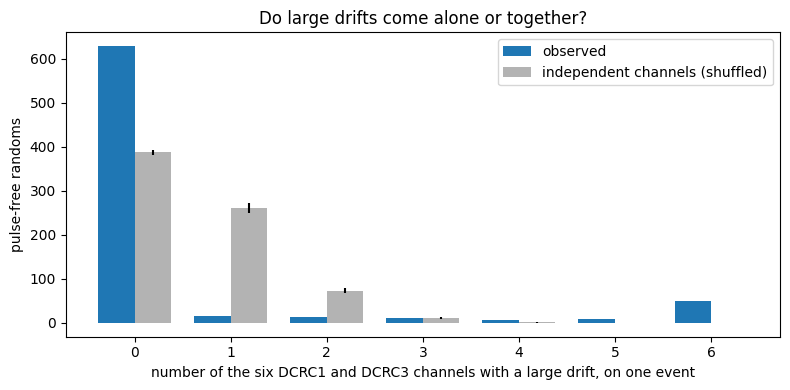

In [5]:
rng = np.random.default_rng(0)
dm = np.array([info[k]["drift"][R] for k in mixed]).T                    # (pulse-free randoms, six channels)
threshold = np.percentile(np.abs(dm), 90, axis=0)
large = np.abs(dm) > threshold
n_large = large.sum(axis=1)
observed = np.bincount(n_large, minlength=len(mixed) + 1)

shuffles = np.array([np.bincount((np.abs(np.array([rng.permutation(dm[:, j]) for j in range(dm.shape[1])]).T) > threshold).sum(axis=1),
                                 minlength=len(mixed) + 1) for _ in range(200)])
expected, spread = shuffles.mean(axis=0), shuffles.std(axis=0)
print(f"large drift = |drift| above the 90th percentile of that channel: " + ", ".join(f"{pch.channel_name(*k)} {t:.1f}" for k, t in zip(mixed, threshold)) + " counts")
print(f"{'channels with a large drift':<30}{'observed':>10}{'if independent':>18}")
for m in range(len(mixed) + 1):
    print(f"{m:<30}{observed[m]:>10}{expected[m]:>12.1f} +- {spread[m]:.1f}")

fig, ax = plt.subplots(figsize=(8, 4))
w = 0.38
ax.bar(np.arange(len(observed)) - w / 2, observed, w, label="observed")
ax.bar(np.arange(len(observed)) + w / 2, expected, w, yerr=spread, label="independent channels (shuffled)", color="0.7")
ax.set_xlabel("number of the six DCRC1 and DCRC3 channels with a large drift, on one event")
ax.set_ylabel("pulse-free randoms"); ax.legend(); ax.set_title("Do large drifts come alone or together?")
fig.tight_layout()
plt.savefig(f"figures/drift-alone-or-together-{DUMP}.png", dpi=110)
plt.show()

## 5. The odd events: one channel drifts, the others do not

For each random, how far is each channel's drift from what the *other five* DCRC1 and DCRC3 channels say? The residual is the channel's drift minus the median drift of the other five, in units of that channel's typical scatter of such residuals (the median absolute deviation, MAD, scaled to a standard deviation). The **outlier score** of an event is its largest residual in these units; an event counts as **odd** if its score is above 5 *and* the residual is at least 5 counts (many events have almost no scatter in their residuals, which would otherwise inflate the score). The table lists the events with the highest score and which channel it is. The figure shows the four highest, one column per event, one row per working channel: the baseline-subtracted trace, the fitted line in red, and the drift in the corner.

  event   score  channel    its drift  median of the others
  10507    50.4  Side2pA       -179.7                 -20.8
  10027    43.5  Side2pF         -4.0                -112.5
  10603    39.6  Side2pA       -183.2                 -58.3
  10704    29.9  Side2pA       -111.8                 -17.5
  10171    27.4  Side2pA       -121.9                 -35.6
  10524    26.3  Side2pA       -126.3                 -43.5
  10920    25.2  Side2pA       -149.5                 -70.2
  10487    24.2  Side2pA        -84.6                  -8.1
  10970    24.0  Side2pA       -135.8                 -60.1
  10520    23.6  Side2pA       -199.7                -125.3
  10877    23.2  Side2pA       -114.4                 -41.2
  10703    21.1  Side2pA        -86.8                 -20.4
odd pulse-free randoms (score above 5 and residual at least 5 counts): 122 of 734


C:\Users\villanoa\AppData\Local\Temp\ipykernel_12084\362739195.py:14: UserWarning: channel_name is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and channels 0 to 3 = board inputs pA to pD is assumed; not yet confirmed against the run's ODB
  print(f"{event_numbers[rand_idx[o]]:>7}{event_score[o]:>8.1f}  {pch.channel_name(*mixed[who[o]]):<10}{dm[o, who[o]]:>10.1f}{others_median[o, who[o]]:>22.1f}")


C:\Users\villanoa\AppData\Local\Temp\ipykernel_12084\362739195.py:32: UserWarning: channel_name is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and channels 0 to 3 = board inputs pA to pD is assumed; not yet confirmed against the run's ODB
  ax.set_ylabel(pch.channel_name(*k), fontsize=10)
C:\Users\villanoa\AppData\Local\Temp\ipykernel_12084\362739195.py:34: UserWarning: channel_name is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and channels 0 to 3 = board inputs pA to pD is assumed; not yet confirmed against the run's ODB
  ax.set_title(f"event {event_numbers[e]}  (score {event_score[o]:.1f}, odd channel {pch.channel_name(*mixed[who[o]])})", fontsize=10)


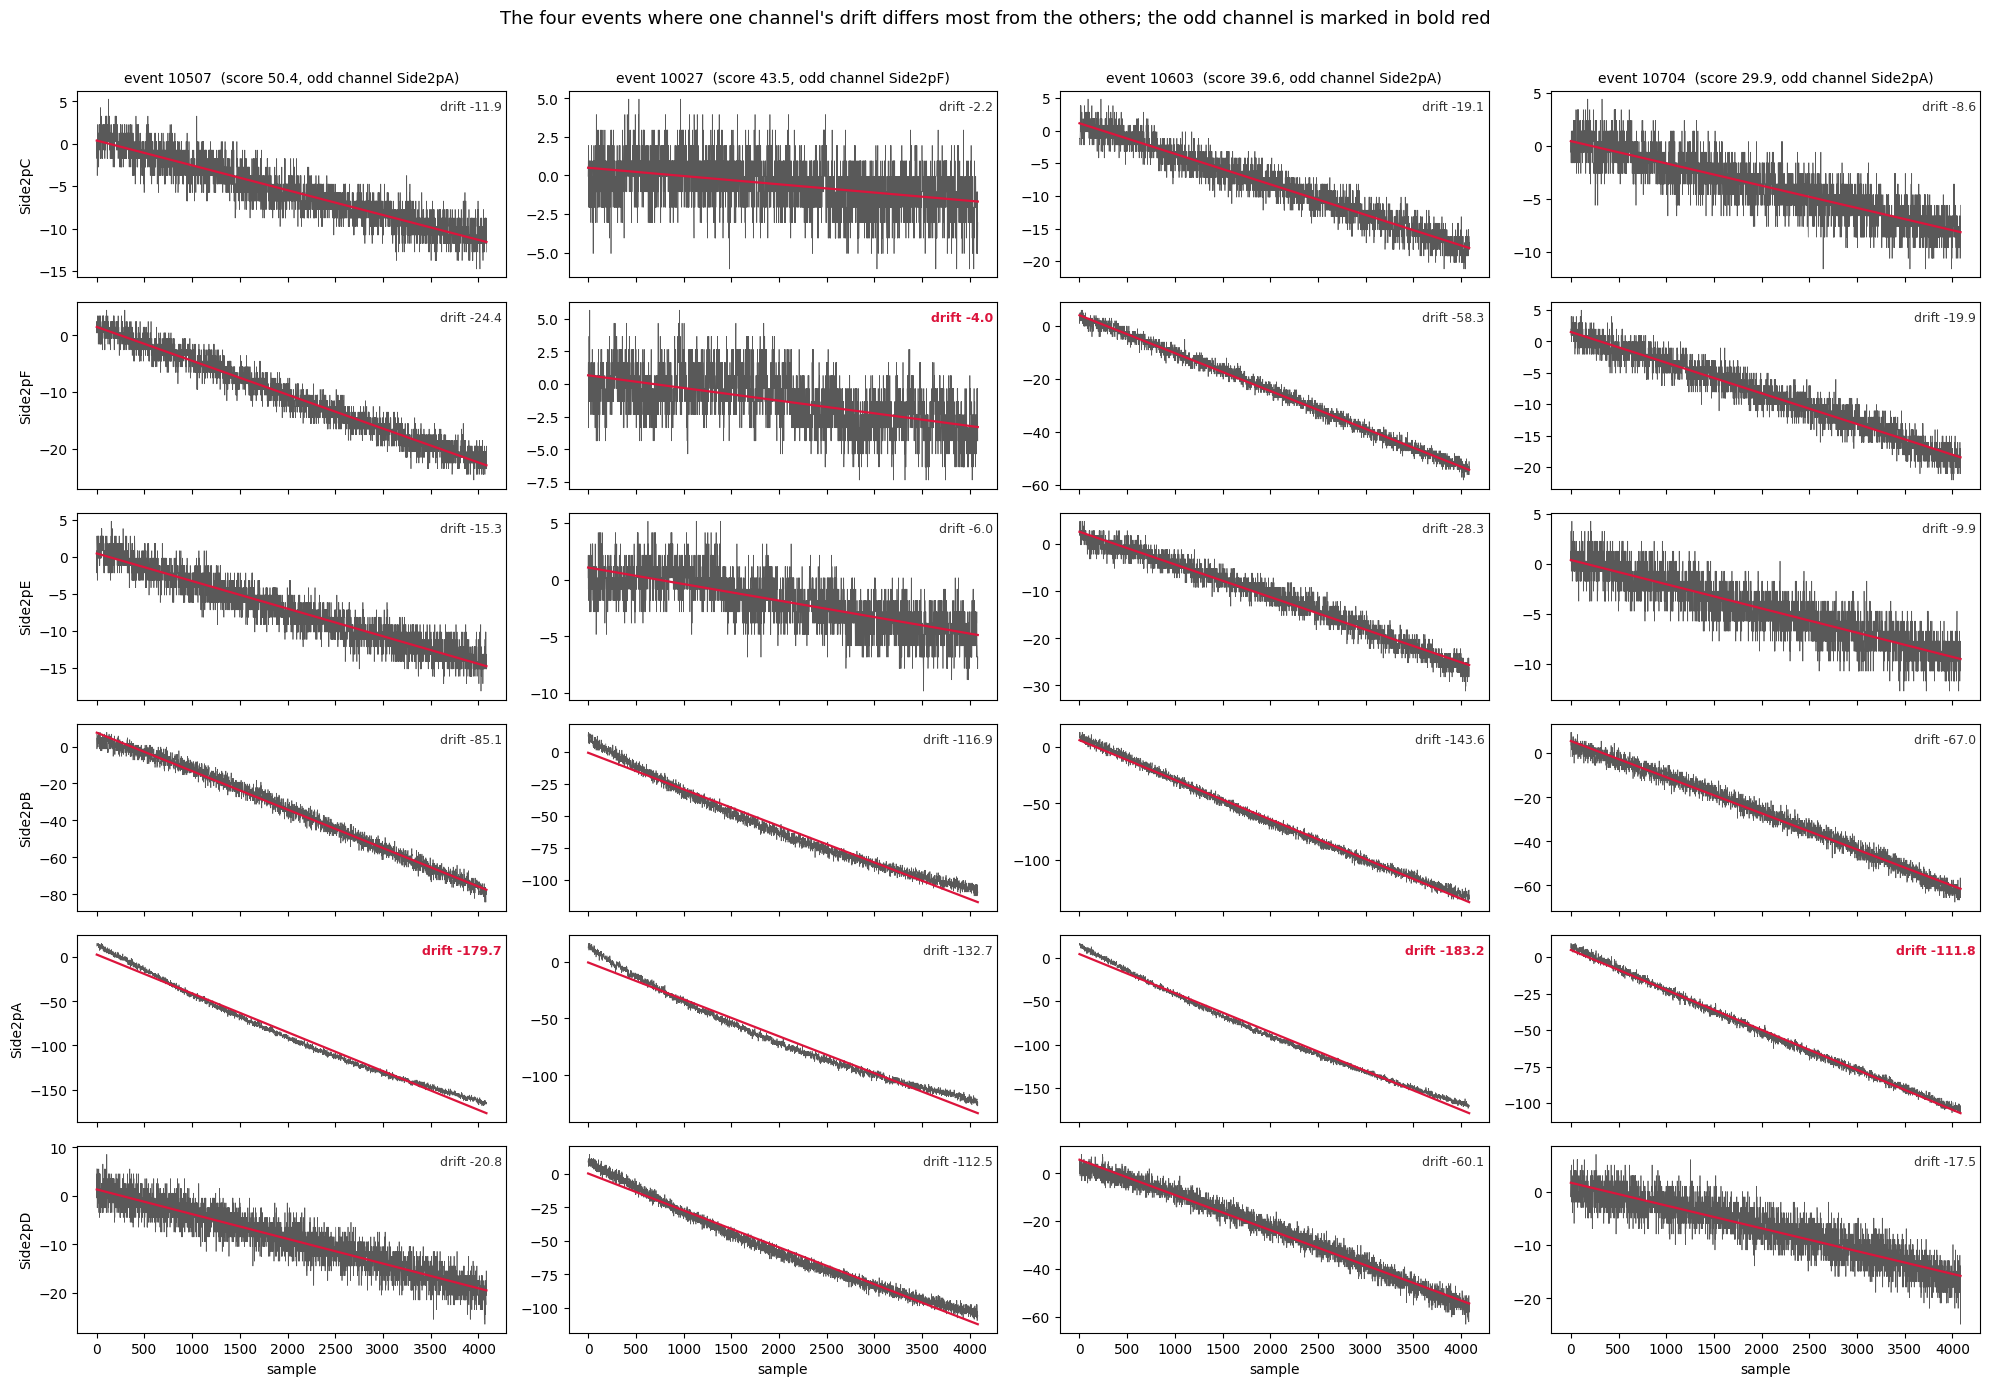

In [6]:
others_median = np.array([np.median(np.delete(dm, j, axis=1), axis=1) for j in range(dm.shape[1])]).T
resid = dm - others_median
mad = np.median(np.abs(resid - np.median(resid, axis=0)), axis=0) * 1.4826
score = np.abs(resid) / mad
event_score = score.max(axis=1)
who = score.argmax(axis=1)
resid_odd = np.abs(resid)[np.arange(len(who)), who]                     # size of the odd channel's residual, counts
odd = (event_score > 5) & (resid_odd >= 5)
rand_idx = np.flatnonzero(R)
order = np.argsort(np.where(odd, event_score, 0))[::-1]

print(f"{'event':>7}{'score':>8}  {'channel':<10}{'its drift':>10}{'median of the others':>22}")
for o in order[:min(12, max(odd.sum(), 1))]:
    print(f"{event_numbers[rand_idx[o]]:>7}{event_score[o]:>8.1f}  {pch.channel_name(*mixed[who[o]]):<10}{dm[o, who[o]]:>10.1f}{others_median[o, who[o]]:>22.1f}")
print(f"odd pulse-free randoms (score above 5 and residual at least 5 counts): {odd.sum()} of {len(event_score)}")

shown = order[:min(4, max(odd.sum(), 1))]
batch = {k: pio.load_channel_batch(cdms, det_ids[k[0]], k[1])[1] for k in working}
t = np.arange(n_samples)
fig, axes = plt.subplots(len(working), len(shown), figsize=(20, 2.1 * len(working) + 1.5), sharex=True)
for j, o in enumerate(shown):
    e = rand_idx[o]
    for i, k in enumerate(working):
        ax = axes[i, j]
        trace = processed(batch[k][e:e + 1])[0]
        ax.plot(t, trace, linewidth=0.5, color="0.35")
        ax.plot(t, info[k]["slope"][e] * t + info[k]["offset"][e], color="crimson", linewidth=1.6)
        is_odd = k in mixed and mixed.index(k) == who[o]
        ax.text(0.99, 0.95, f"drift {info[k]['drift'][e]:+.1f}", transform=ax.transAxes, ha="right", va="top", fontsize=9,
                color="crimson" if is_odd else "0.2", fontweight="bold" if is_odd else "normal")
        if j == 0:
            ax.set_ylabel(pch.channel_name(*k), fontsize=10)
        if i == 0:
            ax.set_title(f"event {event_numbers[e]}  (score {event_score[o]:.1f}, odd channel {pch.channel_name(*mixed[who[o]])})", fontsize=10)
        if i == len(working) - 1:
            ax.set_xlabel("sample")
fig.suptitle("The four events where one channel's drift differs most from the others; the odd channel is marked in bold red", fontsize=13)
fig.tight_layout(rect=(0, 0, 1, 0.97))
plt.savefig(f"figures/drift-odd-events-{DUMP}.png", dpi=100)
plt.show()

## 6. Does the quiet-noise cut see them?

For the odd events of section 5, in the odd channel: does that channel fail the quiet-noise cut, and do the other channels of the event pass it? If the cut is evaluated on each channel's own trace, an odd event would fail in the odd channel only, and a global cut over all channels would then throw the whole event away because of one channel.

In [7]:
rows = []
for o in np.flatnonzero(odd):
    e = rand_idx[o]
    k_odd = mixed[who[o]]
    others = [k for k in working if k != k_odd]
    rows.append((info[k_odd]["quiet"][e], np.mean([info[k]["quiet"][e] for k in others])))
rows = np.array(rows, dtype=float)
print(f"odd events: {odd.sum()}")
if odd.sum():
    print(f"  the odd channel fails the quiet-noise cut:        {int((rows[:, 0] == 0).sum())} of {odd.sum()}")
    print(f"  all other channels of the event pass the cut:      {int((rows[:, 1] == 1).sum())} of {odd.sum()}")
    print(f"  the odd channel fails and every other one passes:  {int(((rows[:, 0] == 0) & (rows[:, 1] == 1)).sum())} of {odd.sum()}")
passes_all = np.array([all(info[k]["quiet"][e] for k in working) for e in rand_idx])
print(f"for comparison, pulse-free randoms that pass the cut in every working channel (the global cut): {passes_all.sum()} of {len(rand_idx)}")
print(f"  of those, odd: {(passes_all & odd).sum()}")

odd events: 122
  the odd channel fails the quiet-noise cut:        121 of 122
  all other channels of the event pass the cut:      0 of 122
  the odd channel fails and every other one passes:  0 of 122
for comparison, pulse-free randoms that pass the cut in every working channel (the global cut): 34 of 734
  of those, odd: 0


## 7. One channel sees a pulse, the others do not

Among the randoms that contain a pulse (section 1), how many of the six DCRC1 and DCRC3 channels see it? A particle interaction seen by every channel of a board would give 3 per board; one that is local to a part of the face, or a pulse in only one channel, gives fewer. The NaI trigger input (DCRC4 pA) is not a sensor and is not counted; it shows no pulse-like trace either. The table counts the events by which boards have a pulse, and the figure shows the number of channels with a pulse, per event.

274 randoms contain a pulse; the NaI trigger input (NaI (DCRC4 pA)) shows a pulse-like trace in 0 of them

boards with a pulse         randoms
DCRC1 only                       16
DCRC3 only                       32
DCRC1 and DCRC3                 226

number of the six channels with a pulse -> events: {1: 17, 2: 25, 3: 19, 4: 5, 5: 4, 6: 204}

which channels see the pulse when only some do (70 events with 1 to 5 channels):
  Side2pC   sees a pulse in   10 of them
  Side2pF   sees a pulse in   36 of them
  Side2pE   sees a pulse in   13 of them
  Side2pB   sees a pulse in   33 of them
  Side2pA   sees a pulse in   49 of them
  Side2pD   sees a pulse in   23 of them


C:\Users\villanoa\AppData\Local\Temp\ipykernel_12084\3611397434.py:4: UserWarning: channel_info is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and channels 0 to 3 = board inputs pA to pD is assumed; not yet confirmed against the run's ODB
  board_of = [pch.channel_info(*k).dcrc for k in mixed]
C:\Users\villanoa\AppData\Local\Temp\ipykernel_12084\3611397434.py:8: UserWarning: channel_label is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and channels 0 to 3 = board inputs pA to pD is assumed; not yet confirmed against the run's ODB
  print(f"{pulse_events.sum()} randoms contain a pulse; the NaI trigger input ({pch.channel_label(*nai_key)}) shows a pulse-like trace in {(is_random & info[nai_key]['pulse']).sum()} of them")
C:\Users\villanoa\Research\NSDF-Data-buddy2\python\pulse_channels.py:135: UserWarning: channel_info is marked under_development: the d

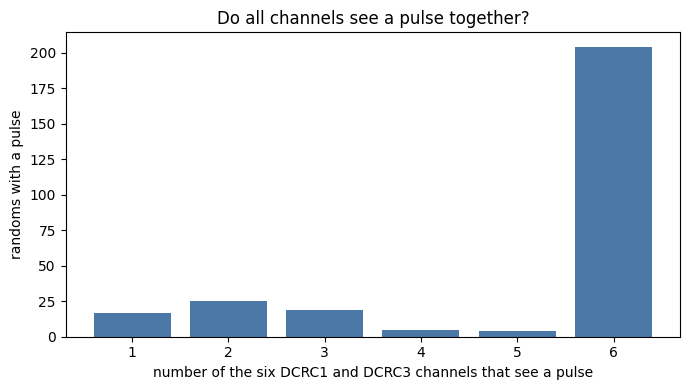

In [8]:
pulse_events = is_random & has_pulse.any(axis=1)
mixed_cols = [working.index(k) for k in mixed]
hp = has_pulse[:, mixed_cols]                                          # (events, six channels)
board_of = [pch.channel_info(*k).dcrc for k in mixed]
d1 = [i for i, b in enumerate(board_of) if b == "DCRC1"]
d3 = [i for i, b in enumerate(board_of) if b == "DCRC3"]
n_pulse = hp[pulse_events].sum(axis=1)
print(f"{pulse_events.sum()} randoms contain a pulse; the NaI trigger input ({pch.channel_label(*nai_key)}) shows a pulse-like trace in {(is_random & info[nai_key]['pulse']).sum()} of them")
print()
print(f"{'boards with a pulse':<26}{'randoms':>9}")
for label, mask in [("DCRC1 only", hp[:, d1].any(1) & ~hp[:, d3].any(1)),
                    ("DCRC3 only", ~hp[:, d1].any(1) & hp[:, d3].any(1)),
                    ("DCRC1 and DCRC3", hp[:, d1].any(1) & hp[:, d3].any(1))]:
    print(f"{label:<26}{(pulse_events & mask).sum():>9}")
print()
print("number of the six channels with a pulse -> events:", {m: int((n_pulse == m).sum()) for m in range(1, 7)})
print()
partial = pulse_events & (hp.sum(axis=1) < 6)
print(f"which channels see the pulse when only some do ({partial.sum()} events with 1 to 5 channels):")
for i, k in enumerate(mixed):
    print(f"  {pch.channel_name(*k):<9} sees a pulse in {int((partial & hp[:, i]).sum()):>4} of them")

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(range(1, 7), [(n_pulse == m).sum() for m in range(1, 7)], color="#4c78a8")
ax.set_xlabel("number of the six DCRC1 and DCRC3 channels that see a pulse"); ax.set_ylabel("randoms with a pulse")
ax.set_title("Do all channels see a pulse together?")
fig.tight_layout()
plt.savefig(f"figures/drift-pulse-channels-{DUMP}.png", dpi=110)
plt.show()

## 8. What the drift and the pulses are (this dump only)

- **Two populations.** 274 of the 1008 randoms (27%) contain a pulse in at least one DCRC1 or DCRC3 channel: a fast step of tens to hundreds of counts with a slow recovery. The other 734 are pulse-free. These pulses are the second, smaller group (`log10(ratio)` from 2 to 2.5) that `quiet-cut-failures-buddy.ipynb` left open. The NaI trigger input never shows a pulse-like trace.
- **The pulse-free randoms ramp.** The median drift is a sag of 6 to 12 counts across the trace on the six DCRC1 and DCRC3 channels (16th to 84th percentile: about 3 to 35 counts, with a tail down to more than 100 counts), largest on the DCRC3 channels.
- **The channels drift together, and large drifts come together.** The rank correlation between the drifts of any two of the six channels is 0.82 to 0.97 (median 0.91). Of the 734 pulse-free randoms, 629 have no channel with a large drift (388 expected if the channels were independent), 50 have all six (0 expected), and only 15 have exactly one, against 261 expected. A single channel with a large drift while the others have none is about 17 times rarer than chance, so it is essentially absent.
- **The "odd" events are not a separate phenomenon.** The outlier score flags 122 of the 734, but in the events shown (section 5) all six channels ramp smoothly and together, and the flagged channel is simply the one with the largest ramp: `Side2pA` falls by 112 to 183 counts in events 10507, 10603 and 10704, against 9 to 144 counts in the others. The ramps are slightly curved, like a slow relaxation, with an amplitude that depends on the channel. The one board-level difference among them is event 10027: the DCRC3 channels fall by 112 to 133 counts while the DCRC1 channels fall by only 2 to 6.
- **The cut never sees one channel alone.** In 121 of the 122 odd events the flagged channel fails the quiet-noise cut, and in none of them do all the other channels pass. So there are no events where one channel fails alone and the rest pass; a global cut over all channels does not lose events because of a single odd channel.
- **Pulses are mostly seen by every channel.** Of the 274 events with a pulse, 204 show it in all six DCRC1 and DCRC3 channels, 226 on both boards, 16 on DCRC1 only and 32 on DCRC3 only. The 70 events where only some channels see it involve `Side2pA` (49), `Side2pF` (36) and `Side2pB` (33) most often, and `Side2pC` (10) and `Side2pE` (13) least. A pulse is flagged when it is large against the noise, so a pulse that is only small in some channels would look partial; this has not been checked.

## Next steps

- Test whether the ramp is the tail of an earlier pulse: for each pulse-free random, compare the size of its ramp with the time since the previous event that contains a pulse (the dump's timestamps have one-second resolution, so this needs the event order and, if possible, finer timing).
- Fit the ramp with an exponential and see whether its time constant is the same in every channel and every event; a common relaxation with a channel-dependent amplitude would be a property of the readout.
- Look at the partial pulses (70 events seen by 1 to 5 channels), at their amplitude in each channel, and at whether they are real pulses below the flag in some channels.
- Look at event 10027, where the DCRC3 channels ramp by more than 100 counts and the DCRC1 channels by a few, to see what separates the boards.
- Decide whether the global cut should be built from the ramp (and a cut on its size) as well as the excursion band.
- Repeat with the other dumps of the series (F0002 to F0005) with `pio.load_channel_batch_multi`.